In [1]:

import pandas as pd

# Đọc dữ liệu CSV
df = pd.read_csv('tiktok_shop_sales_cleaned.csv')

# Hiển thị 5 dòng đầu tiên
display(df.head())

# Kiểm tra kích thước dữ liệu
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

# Liệt kê tên các cột
print("\nDanh sách các cột:")
print(df.columns.tolist())


,Order_ID,Order_Date,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Shipping_City,Device_Type,Product_ID,Product_Name,...,Payment_Method,Order_Status,Product_Rating,Review_Count,Shop_ID,Shop_Name,Traffic_Source,Creator_Name,Video_Views,Is_Anomaly
0,TTS-2024-005112,2024-01-01 07:15:55,CUST-01053,Nguyễn Hoàng Huy,25,Nam,Hà Nội,Android,PROD-T02,Cáp sạc nhanh 3 đầu Type-C Lightning Baseus,...,Cod (Thanh Toán Khi Nhận Hàng),Hoàn thành,5.0,17800,SHOP-007,Audio SoundMaster Mall,Livestream TikTok,Võ Hà Linh,633634,0
1,TTS-2024-000128,2024-01-01 11:48:28,CUST-01140,Đỗ Thị Linh,32,Nữ,Hà Nội,iOS (iPhone),PROD-F03,Chân váy chữ A xếp ly ngắn năng động,...,Cod (Thanh Toán Khi Nhận Hàng),Hoàn thành,4.0,6500,SHOP-004,Bếp Mẹ Nấu & Đồ Ăn Vặt,Livestream TikTok,Diệp Lê,808313,0
2,TTS-2024-006987,2024-01-01 12:08:17,CUST-00967,Phạm Gia Bảo,40,Nam,Hà Nội,iOS (iPhone),PROD-T05,Ốp lưng iPhone silicon trong suốt chống sốc,...,Cod (Thanh Toán Khi Nhận Hàng),Hoàn thành,5.0,29000,SHOP-003,TechPro Digital Vietnam,Video ngắn gắn link,Quyền Leo Daily,1598325,0
3,TTS-2024-007647,2024-01-01 12:35:42,CUST-00321,Hoàng Phương Thảo,23,Nữ,Tp. Hồ Chí Minh,iOS (iPhone),PROD-S01,Bánh tráng phơi sương muối nhuyễn bơ hành,...,Ví Điện Tử (Zalopay/Momo),Hoàn thành,3.0,34000,SHOP-007,Audio SoundMaster Mall,Video ngắn gắn link,Gian hàng tự Live (Shop Direct),871173,0
4,TTS-2024-003627,2024-01-01 13:10:06,CUST-00686,Bùi Ngọc Hà,27,Nữ,Hà Nội,Android,PROD-F05,Váy hoa nhí tay bồng phong cách Hàn Quốc,...,Chuyển Khoản Qr,Hoàn thành,5.0,4300,SHOP-008,SkinCare Hub Chính Hãng,Showcase (Cửa hàng),Bán trực tiếp (Không qua KOC),64602,0


Số dòng: 8500
Số cột: 27

Danh sách các cột:
['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Customer_Age', 'Customer_Gender', 'Shipping_City', 'Device_Type', 'Product_ID', 'Product_Name', 'Main_Category', 'Sub_Category', 'Unit_Price', 'Quantity', 'Discount_Amount', 'Shipping_Fee', 'Total_Amount', 'Payment_Method', 'Order_Status', 'Product_Rating', 'Review_Count', 'Shop_ID', 'Shop_Name', 'Traffic_Source', 'Creator_Name', 'Video_Views', 'Is_Anomaly']


In [2]:

# Kiểm tra kiểu dữ liệu
display(df.dtypes.to_frame(name="Data Type"))

# Kiểm tra giá trị thiếu
missing = df.isnull().sum()
print("Tổng số ô thiếu:", missing.sum())
print(missing[missing > 0])

# Kiểm tra dữ liệu trùng lặp
print("Số dòng trùng lặp:", df.duplicated().sum())

# Thống kê trạng thái đơn hàng
if "Order_Status" in df.columns:
    print(df["Order_Status"].value_counts(dropna=False))

# Thống kê nhãn bất thường
if "Is_Anomaly" in df.columns:
    print(df["Is_Anomaly"].value_counts(dropna=False))

# Kiểm tra các cột phục vụ RFM
for col in ["Customer_ID", "Order_ID", "Order_Date"]:
    print(col, ":", col in df.columns)


,Data Type
Order_ID,object
Order_Date,object
Customer_ID,object
Customer_Name,object
Customer_Age,int64
Customer_Gender,object
Shipping_City,object
Device_Type,object
Product_ID,object
Product_Name,object


Tổng số ô thiếu: 0
Series([], dtype: int64)
Số dòng trùng lặp: 0
Order_Status
Hoàn thành               6926
Đang vận chuyển           651
Đã hủy                    522
Hoàn trả / Khiếu nại      276
Giao không thành công     125
Name: count, dtype: int64
Is_Anomaly
0    8150
1     350
Name: count, dtype: int64
Customer_ID : True
Order_ID : True
Order_Date : True


In [3]:

# Xem tên các cột và một số giá trị mẫu
print(df.columns.tolist())

cols = ["Customer_ID", "Order_ID", "Order_Date"]
display(df[cols].head())

# Tìm các cột có thể dùng để tính giá trị chi tiêu
print("\nCác cột liên quan đến tiền và số lượng:")
print([
    col for col in df.columns
    if any(word in col.lower() for word in
           ["amount", "price", "revenue", "total", "quantity", "spend"])
])


['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Customer_Age', 'Customer_Gender', 'Shipping_City', 'Device_Type', 'Product_ID', 'Product_Name', 'Main_Category', 'Sub_Category', 'Unit_Price', 'Quantity', 'Discount_Amount', 'Shipping_Fee', 'Total_Amount', 'Payment_Method', 'Order_Status', 'Product_Rating', 'Review_Count', 'Shop_ID', 'Shop_Name', 'Traffic_Source', 'Creator_Name', 'Video_Views', 'Is_Anomaly']


,Customer_ID,Order_ID,Order_Date
0,CUST-01053,TTS-2024-005112,2024-01-01 07:15:55
1,CUST-01140,TTS-2024-000128,2024-01-01 11:48:28
2,CUST-00967,TTS-2024-006987,2024-01-01 12:08:17
3,CUST-00321,TTS-2024-007647,2024-01-01 12:35:42
4,CUST-00686,TTS-2024-003627,2024-01-01 13:10:06



Các cột liên quan đến tiền và số lượng:
['Unit_Price', 'Quantity', 'Discount_Amount', 'Total_Amount']


In [4]:

# Kiểm tra giá trị đơn hàng theo trạng thái
display(
    df.groupby("Order_Status")["Total_Amount"]
    .agg(["count", "min", "mean", "max", "sum"])
    .round(2)
)

# Kiểm tra kiểu dữ liệu và giá trị mẫu
print("Kiểu dữ liệu Total_Amount:", df["Total_Amount"].dtype)
display(df[["Order_ID", "Order_Date", "Order_Status", "Total_Amount"]].head(10))


,count,min,mean,max,sum
Order_Status,,,,,
Giao không thành công,125,35100,254236.00,1596000,31779500
Hoàn thành,6926,19600,227486.66,1755000,1575572600
Hoàn trả / Khiếu nại,276,25200,254475.91,1527000,70235350
Đang vận chuyển,651,22400,219829.88,1512000,143109250
Đã hủy,522,22400,227815.90,1566000,118919900


Kiểu dữ liệu Total_Amount: int64


,Order_ID,Order_Date,Order_Status,Total_Amount
0,TTS-2024-005112,2024-01-01 07:15:55,Hoàn thành,84550
1,TTS-2024-000128,2024-01-01 11:48:28,Hoàn thành,150000
2,TTS-2024-006987,2024-01-01 12:08:17,Hoàn thành,139000
3,TTS-2024-007647,2024-01-01 12:35:42,Hoàn thành,65000
4,TTS-2024-003627,2024-01-01 13:10:06,Hoàn thành,267000
5,TTS-2024-002852,2024-01-01 13:59:39,Hoàn thành,183000
6,TTS-2024-002311,2024-01-01 19:07:52,Hoàn thành,527250
7,TTS-2024-001746,2024-01-01 19:12:48,Hoàn trả / Khiếu nại,432300
8,TTS-2024-001631,2024-01-01 19:23:21,Hoàn thành,117000
9,TTS-2024-006420,2024-01-01 19:27:44,Hoàn thành,163550


In [5]:

# Chọn các đơn hàng đã hoàn thành
df_rfm_source = df[df["Order_Status"] == "Hoàn thành"].copy()

# Kiểm tra số lượng đơn hàng được sử dụng
print("Số đơn hàng hoàn thành:", len(df_rfm_source))
print("Số khách hàng:", df_rfm_source["Customer_ID"].nunique())

# Chuyển ngày đặt hàng sang kiểu datetime
df_rfm_source["Order_Date"] = pd.to_datetime(
    df_rfm_source["Order_Date"], errors="coerce"
)

# Kiểm tra ngày không hợp lệ
print("Số ngày đặt hàng không hợp lệ:",
      df_rfm_source["Order_Date"].isna().sum())

# Kiểm tra giá trị tiền
print("Số giá trị Total_Amount không hợp lệ:",
      df_rfm_source["Total_Amount"].isna().sum())
print("Số giá trị Total_Amount âm:",
      (df_rfm_source["Total_Amount"] < 0).sum())


Số đơn hàng hoàn thành: 6926
Số khách hàng: 1393
Số ngày đặt hàng không hợp lệ: 0
Số giá trị Total_Amount không hợp lệ: 0
Số giá trị Total_Amount âm: 0


In [6]:

# Xác định ngày chốt dữ liệu
snapshot_date = df_rfm_source["Order_Date"].max() + pd.Timedelta(days=1)

# Tính các chỉ số RFM theo khách hàng
rfm = df_rfm_source.groupby("Customer_ID").agg(
    Recency=("Order_Date", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Order_ID", "nunique"),
    Monetary=("Total_Amount", "sum")
).reset_index()

# Hiển thị kết quả
display(rfm.head(10))

print("Số khách hàng:", len(rfm))
print("Số giá trị thiếu:", rfm.isnull().sum().sum())
print("Số dòng trùng:", rfm.duplicated(subset=["Customer_ID"]).sum())


,Customer_ID,Recency,Frequency,Monetary
0,CUST-00001,27,6,1380700
1,CUST-00002,199,2,525250
2,CUST-00003,46,4,1126600
3,CUST-00004,36,7,1234850
4,CUST-00005,98,4,1129550
5,CUST-00006,74,3,787050
6,CUST-00007,26,5,829500
7,CUST-00008,95,2,404500
8,CUST-00009,30,4,891600
9,CUST-00010,26,5,505000


Số khách hàng: 1393
Số giá trị thiếu: 0
Số dòng trùng: 0


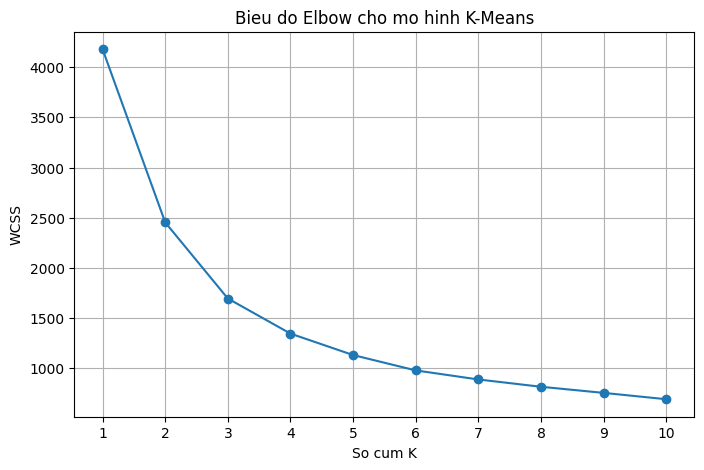

In [7]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Chọn các chỉ số RFM
rfm_features = rfm[["Recency", "Frequency", "Monetary"]]

# Chuẩn hóa dữ liệu
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

# Tính WCSS với các giá trị K khác nhau
wcss = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(rfm_scaled)
    wcss.append(model.inertia_)

# Vẽ biểu đồ Elbow
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), wcss, marker="o")
plt.xlabel("So cum K")
plt.ylabel("WCSS")
plt.title("Bieu do Elbow cho mo hinh K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

K = 2: Silhouette Score = 0.3555
K = 3: Silhouette Score = 0.3596
K = 4: Silhouette Score = 0.3195
K = 5: Silhouette Score = 0.3297
K = 6: Silhouette Score = 0.2958
K = 7: Silhouette Score = 0.2720
K = 8: Silhouette Score = 0.2726
K = 9: Silhouette Score = 0.2734
K = 10: Silhouette Score = 0.2802


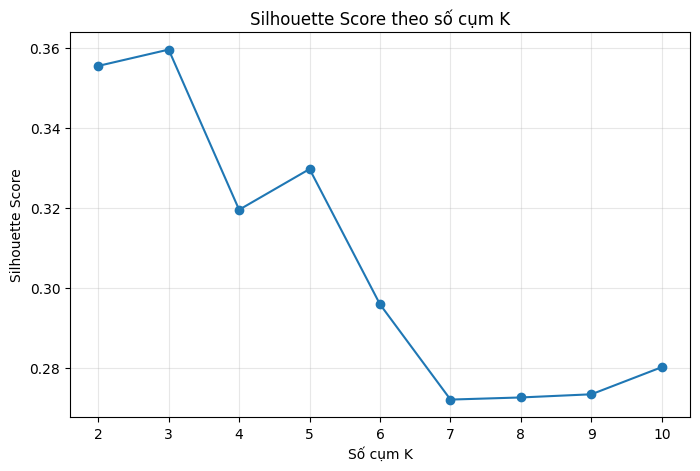

In [8]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)
    score = silhouette_score(rfm_scaled, labels)
    silhouette_scores.append(score)

    print(f"K = {k}: Silhouette Score = {score:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Số cụm K")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score theo số cụm K")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()


In [9]:


# Phân cụm khách hàng thành 3 nhóm
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

# Kiểm tra số khách hàng trong mỗi cụm
print(rfm["Cluster"].value_counts().sort_index())

# Xem đặc điểm RFM trung bình của từng cụm
cluster_summary = rfm.groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

display(cluster_summary)


Cluster
0    215
1    481
2    697
Name: count, dtype: int64


,Recency,Frequency,Monetary
Cluster,,,
0,157.16,2.87,665835.12
1,33.28,7.20,1788366.01
2,41.26,4.08,820967.00


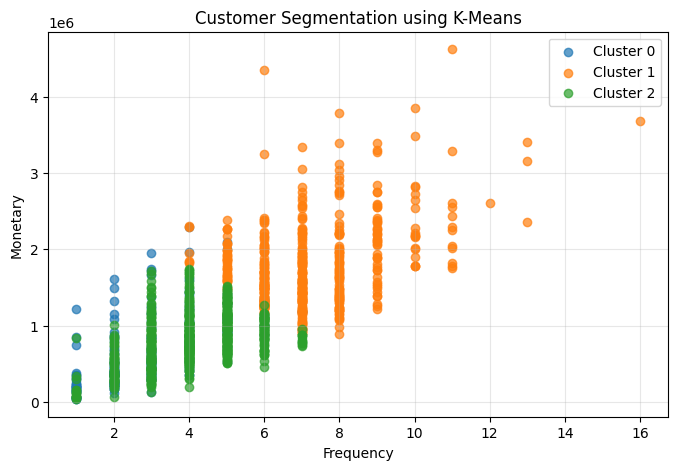

In [10]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for cluster in sorted(rfm["Cluster"].unique()):
    data = rfm[rfm["Cluster"] == cluster]
    plt.scatter(
        data["Frequency"],
        data["Monetary"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel("Frequency")
plt.ylabel("Monetary")
plt.title("Customer Segmentation using K-Means")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [11]:
print(df["Order_Status"].value_counts())

Order_Status
Hoàn thành               6926
Đang vận chuyển           651
Đã hủy                    522
Hoàn trả / Khiếu nại      276
Giao không thành công     125
Name: count, dtype: int64


In [12]:
# Mã hóa trạng thái đơn hàng thành biến mục tiêu y
cancel_return_statuses = [
    "Đã hủy",
    "Hoàn trả / Khiếu nại",
    "Giao không thành công"
]

y = df["Order_Status"].isin(cancel_return_statuses).astype(int)

print("Phân bố nhãn mục tiêu y:")
print(y.value_counts().sort_index())

print("\nTỷ lệ phần trăm:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))

Phân bố nhãn mục tiêu y:
Order_Status
0    7577
1     923
Name: count, dtype: int64

Tỷ lệ phần trăm:
Order_Status
0    89.14
1    10.86
Name: proportion, dtype: float64


In [13]:
# Xác định các biến đầu vào theo hướng dẫn bài tập
feature_columns = [
    "Unit_Price",
    "Quantity",
    "Discount_Amount",
    "Shipping_Fee",
    "Payment_Method",
    "Shipping_City",
    "Traffic_Source"
]

X = df[feature_columns].copy()

print("Danh sách biến đầu vào:")
print(X.columns.tolist())

print("\nKích thước tập đặc trưng X:", X.shape)
print("\nKiểu dữ liệu của các biến:")
print(X.dtypes)

print("\nSố giá trị thiếu ở từng biến:")
print(X.isnull().sum())

Danh sách biến đầu vào:
['Unit_Price', 'Quantity', 'Discount_Amount', 'Shipping_Fee', 'Payment_Method', 'Shipping_City', 'Traffic_Source']

Kích thước tập đặc trưng X: (8500, 7)

Kiểu dữ liệu của các biến:
Unit_Price          int64
Quantity            int64
Discount_Amount     int64
Shipping_Fee        int64
Payment_Method     object
Shipping_City      object
Traffic_Source     object
dtype: object

Số giá trị thiếu ở từng biến:
Unit_Price         0
Quantity           0
Discount_Amount    0
Shipping_Fee       0
Payment_Method     0
Shipping_City      0
Traffic_Source     0
dtype: int64


In [14]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Kích thước tập huấn luyện X_train:", X_train.shape)
print("Kích thước tập kiểm tra X_test:", X_test.shape)
print("Kích thước nhãn y_train:", y_train.shape)
print("Kích thước nhãn y_test:", y_test.shape)

print("\nTỷ lệ nhãn trong tập huấn luyện (%):")
print((y_train.value_counts(normalize=True).sort_index() * 100).round(2))

print("\nTỷ lệ nhãn trong tập kiểm tra (%):")
print((y_test.value_counts(normalize=True).sort_index() * 100).round(2))


Kích thước tập huấn luyện X_train: (6800, 7)
Kích thước tập kiểm tra X_test: (1700, 7)
Kích thước nhãn y_train: (6800,)
Kích thước nhãn y_test: (1700,)

Tỷ lệ nhãn trong tập huấn luyện (%):
Order_Status
0    89.15
1    10.85
Name: proportion, dtype: float64

Tỷ lệ nhãn trong tập kiểm tra (%):
Order_Status
0    89.12
1    10.88
Name: proportion, dtype: float64


In [15]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "Payment_Method",
    "Shipping_City",
    "Traffic_Source"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Kích thước X_train sau mã hóa:", X_train_encoded.shape)
print("Kích thước X_test sau mã hóa:", X_test_encoded.shape)
print("Số nhãn y_train:", len(y_train))
print("Số nhãn y_test:", len(y_test))


Kích thước X_train sau mã hóa: (6800, 26)
Kích thước X_test sau mã hóa: (1700, 26)
Số nhãn y_train: 6800
Số nhãn y_test: 1700


In [16]:

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_encoded, y_train)

print("Huấn luyện Random Forest hoàn tất.")
print("Số cây trong mô hình:", len(rf_model.estimators_))
print("Số đặc trưng đầu vào:", rf_model.n_features_in_)


Huấn luyện Random Forest hoàn tất.
Số cây trong mô hình: 100
Số đặc trưng đầu vào: 26


Confusion Matrix:
[[1491   24]
 [ 181    4]]

Accuracy: 0.8794

Classification Report:
                                precision    recall  f1-score   support

   Không hủy / không gặp sự cố       0.89      0.98      0.94      1515
Hủy / hoàn trả / giao thất bại       0.14      0.02      0.04       185

                      accuracy                           0.88      1700
                     macro avg       0.52      0.50      0.49      1700
                  weighted avg       0.81      0.88      0.84      1700



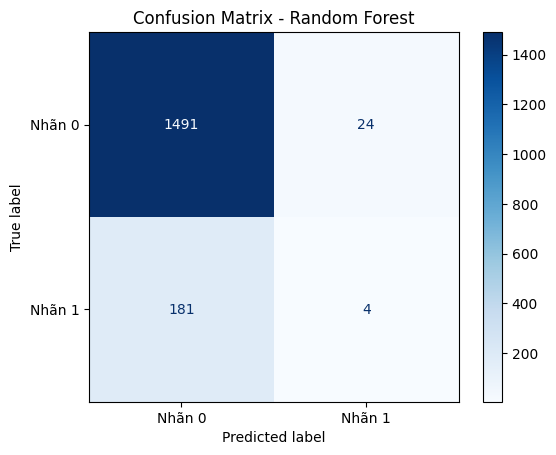

In [17]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report
)
import matplotlib.pyplot as plt

y_pred = rf_model.predict(X_test_encoded)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

print("\nAccuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Không hủy / không gặp sự cố", "Hủy / hoàn trả / giao thất bại"],
    zero_division=0
))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Nhãn 0", "Nhãn 1"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Random Forest")
plt.show()


In [18]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

rf_balanced = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_balanced.fit(X_train_encoded, y_train)

y_pred_balanced = rf_balanced.predict(X_test_encoded)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced, labels=[0, 1]))

print("\nAccuracy:", round(
    accuracy_score(y_test, y_pred_balanced), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_balanced,
    labels=[0, 1],
    target_names=["Nhãn 0", "Nhãn 1"],
    zero_division=0
))


Confusion Matrix:
[[1469   46]
 [ 181    4]]

Accuracy: 0.8665

Classification Report:
              precision    recall  f1-score   support

      Nhãn 0       0.89      0.97      0.93      1515
      Nhãn 1       0.08      0.02      0.03       185

    accuracy                           0.87      1700
   macro avg       0.49      0.50      0.48      1700
weighted avg       0.80      0.87      0.83      1700



In [19]:
print(df["Is_Anomaly"].value_counts())

Is_Anomaly
0    8150
1     350
Name: count, dtype: int64


In [20]:
from sklearn.ensemble import IsolationForest
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import pandas as pd
import matplotlib.pyplot as plt

# Chọn các đặc trưng giao dịch
anomaly_features = [
    "Unit_Price",
    "Quantity",
    "Discount_Amount",
    "Shipping_Fee",
    "Payment_Method",
    "Shipping_City",
    "Traffic_Source"
]

X_anomaly = df[anomaly_features].copy()

# Mã hóa các biến phân loại
categorical_features = [
    "Payment_Method",
    "Shipping_City",
    "Traffic_Source"
]

anomaly_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

X_anomaly_encoded = anomaly_preprocessor.fit_transform(X_anomaly)

# Huấn luyện Isolation Forest
iso_model = IsolationForest(
    contamination=350 / 8500,
    random_state=42
)

anomaly_predictions = iso_model.fit_predict(X_anomaly_encoded)

# Quy đổi kết quả: -1 là bất thường, 1 là bình thường
df["IF_Anomaly"] = (anomaly_predictions == -1).astype(int)

print("Kết quả Isolation Forest:")
print(df["IF_Anomaly"].value_counts().sort_index())

Kết quả Isolation Forest:
IF_Anomaly
0    8150
1     350
Name: count, dtype: int64


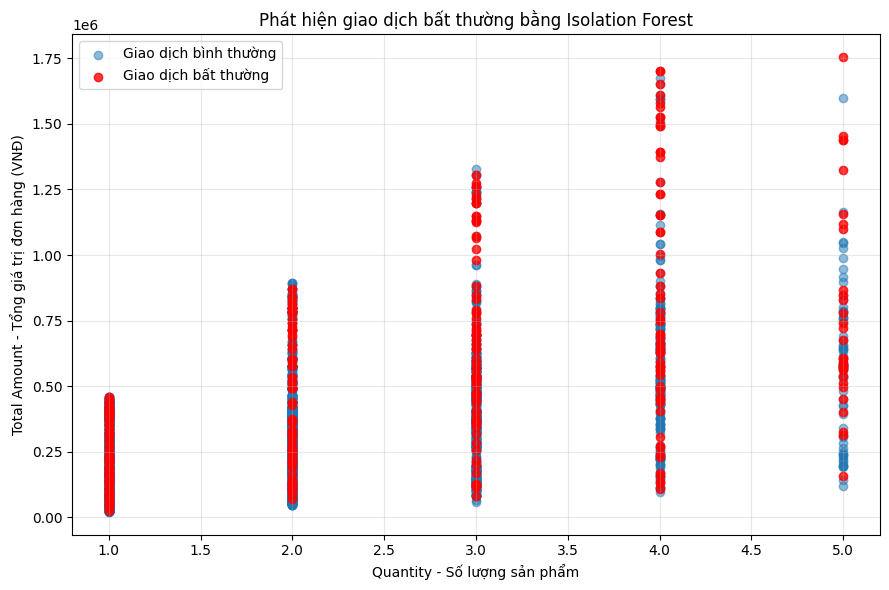

In [21]:

import matplotlib.pyplot as plt

# Chọn hai đặc trưng để trực quan hóa giao dịch
plt.figure(figsize=(9, 6))

normal_data = df[df["IF_Anomaly"] == 0]
anomaly_data = df[df["IF_Anomaly"] == 1]

plt.scatter(
    normal_data["Quantity"],
    normal_data["Total_Amount"],
    label="Giao dịch bình thường",
    alpha=0.5
)

plt.scatter(
    anomaly_data["Quantity"],
    anomaly_data["Total_Amount"],
    color="red",
    label="Giao dịch bất thường",
    alpha=0.8
)

plt.xlabel("Quantity - Số lượng sản phẩm")
plt.ylabel("Total Amount - Tổng giá trị đơn hàng (VNĐ)")
plt.title("Phát hiện giao dịch bất thường bằng Isolation Forest")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [22]:
from sklearn.metrics import confusion_matrix, classification_report

print("So sánh Is_Anomaly gốc với IF_Anomaly:")
print(confusion_matrix(df["Is_Anomaly"], df["IF_Anomaly"]))

print("\nClassification Report:")
print(classification_report(
    df["Is_Anomaly"],
    df["IF_Anomaly"],
    labels=[0, 1],
    zero_division=0
))

So sánh Is_Anomaly gốc với IF_Anomaly:
[[7818  332]
 [ 332   18]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96      8150
           1       0.05      0.05      0.05       350

    accuracy                           0.92      8500
   macro avg       0.51      0.51      0.51      8500
weighted avg       0.92      0.92      0.92      8500



In [23]:

regression_features = [
    "Unit_Price",
    "Quantity",
    "Discount_Amount",
    "Shipping_Fee",
    "Video_Views",
    "Product_Rating",
    "Review_Count"
]

regression_target = "Total_Amount"

required_columns = regression_features + [regression_target]

print("Các cột còn thiếu:")
print([
    col for col in required_columns
    if col not in df.columns
])

print("\nKích thước dữ liệu:", df.shape)

print("\nKiểu dữ liệu:")
print(df[required_columns].dtypes)

print("\nSố giá trị thiếu:")
print(df[required_columns].isnull().sum())


Các cột còn thiếu:
[]

Kích thước dữ liệu: (8500, 28)

Kiểu dữ liệu:
Unit_Price           int64
Quantity             int64
Discount_Amount      int64
Shipping_Fee         int64
Video_Views          int64
Product_Rating     float64
Review_Count         int64
Total_Amount         int64
dtype: object

Số giá trị thiếu:
Unit_Price         0
Quantity           0
Discount_Amount    0
Shipping_Fee       0
Video_Views        0
Product_Rating     0
Review_Count       0
Total_Amount       0
dtype: int64


In [24]:

from sklearn.model_selection import train_test_split

# Tạo tập biến đầu vào X và biến mục tiêu y
X_reg = df[regression_features].copy()
y_reg = df[regression_target].copy()

# Chia dữ liệu theo tỷ lệ 80/20
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print("Kích thước X_reg:", X_reg.shape)
print("Kích thước y_reg:", y_reg.shape)

print("\nKích thước tập huấn luyện:")
print("X_reg_train:", X_reg_train.shape)
print("y_reg_train:", y_reg_train.shape)

print("\nKích thước tập kiểm tra:")
print("X_reg_test:", X_reg_test.shape)
print("y_reg_test:", y_reg_test.shape)


Kích thước X_reg: (8500, 7)
Kích thước y_reg: (8500,)

Kích thước tập huấn luyện:
X_reg_train: (6800, 7)
y_reg_train: (6800,)

Kích thước tập kiểm tra:
X_reg_test: (1700, 7)
y_reg_test: (1700,)


In [25]:

from sklearn.ensemble import RandomForestRegressor

# Khởi tạo mô hình hồi quy
reg_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Huấn luyện mô hình trên tập dữ liệu huấn luyện
reg_model.fit(X_reg_train, y_reg_train)

print("Huấn luyện Random Forest Regressor hoàn tất.")
print("Số cây trong mô hình:", len(reg_model.estimators_))
print("Số biến đầu vào:", reg_model.n_features_in_)


Huấn luyện Random Forest Regressor hoàn tất.
Số cây trong mô hình: 100
Số biến đầu vào: 7


In [26]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Dự đoán giá trị đơn hàng trên tập kiểm tra
y_reg_pred = reg_model.predict(X_reg_test)

# Tính các chỉ số đánh giá
mae = mean_absolute_error(y_reg_test, y_reg_pred)
mse = mean_squared_error(y_reg_test, y_reg_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_reg_test, y_reg_pred)

print("MAE:", round(mae, 2), "VND")
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2), "VND")
print("R-squared (R²):", round(r2, 4))


MAE: 1946.26 VND
MSE: 49190553.64
RMSE: 7013.6 VND
R-squared (R²): 0.9985


In [27]:

# Kiểm tra các biến liên quan đến tổng giá trị đơn hàng
check_columns = [
    "Unit_Price",
    "Quantity",
    "Discount_Amount",
    "Shipping_Fee",
    "Total_Amount"
]

print("10 dòng dữ liệu ban đầu:")
print(df[check_columns].head(10))

# Kiểm tra công thức tổng tiền giả định
df["Estimated_Total"] = (
    df["Unit_Price"] * df["Quantity"]
    - df["Discount_Amount"]
    + df["Shipping_Fee"]
)

df["Total_Difference"] = (
    df["Total_Amount"] - df["Estimated_Total"]
)

print("\nBảng đối chiếu tổng tiền:")
print(
    df[
        [
            "Unit_Price",
            "Quantity",
            "Discount_Amount",
            "Shipping_Fee",
            "Total_Amount",
            "Estimated_Total",
            "Total_Difference"
        ]
    ].head(10)
)

print(
    "\nSố dòng có chênh lệch bằng 0:",
    (df["Total_Difference"] == 0).sum()
)
print("Tổng số dòng:", len(df))


10 dòng dữ liệu ban đầu:
   Unit_Price  Quantity  Discount_Amount  Shipping_Fee  Total_Amount
0       89000         1             4450             0         84550
1      135000         1                0         15000        150000
2       39000         3                0         22000        139000
3       65000         1                0             0         65000
4      245000         1                0         22000        267000
5      210000         1            42000         15000        183000
6      185000         3            27750             0        527250
7      149000         3            44700         30000        432300
8       65000         2            13000             0        117000
9      149000         1             7450         22000        163550

Bảng đối chiếu tổng tiền:
   Unit_Price  Quantity  Discount_Amount  Shipping_Fee  Total_Amount  \
0       89000         1             4450             0         84550   
1      135000         1                0     

In [28]:

# Chọn 5 đặc trưng theo yêu cầu bài tập
anomaly_features = [
    "Total_Amount",
    "Discount_Amount",
    "Shipping_Fee",
    "Quantity",
    "Video_Views"
]

X_anomaly = df[anomaly_features].copy()

print("Kích thước dữ liệu:", X_anomaly.shape)
print("\nKiểu dữ liệu:")
print(X_anomaly.dtypes)

print("\nSố giá trị thiếu:")
print(X_anomaly.isnull().sum())


Kích thước dữ liệu: (8500, 5)

Kiểu dữ liệu:
Total_Amount       int64
Discount_Amount    int64
Shipping_Fee       int64
Quantity           int64
Video_Views        int64
dtype: object

Số giá trị thiếu:
Total_Amount       0
Discount_Amount    0
Shipping_Fee       0
Quantity           0
Video_Views        0
dtype: int64


In [29]:

from sklearn.ensemble import IsolationForest

# Khởi tạo mô hình theo yêu cầu bài tập
iso_model = IsolationForest(
    contamination=0.04,
    random_state=42
)

# Huấn luyện và dự đoán điểm bất thường
anomaly_labels = iso_model.fit_predict(X_anomaly)

# Chuyển kết quả: -1 là bất thường, 1 là bình thường
df["IF_Anomaly_Final"] = (anomaly_labels == -1).astype(int)

print("Phân bố kết quả Isolation Forest:")
print(df["IF_Anomaly_Final"].value_counts().sort_index())

print("\nTỷ lệ phần trăm:")
print(
    (df["IF_Anomaly_Final"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)


Phân bố kết quả Isolation Forest:
IF_Anomaly_Final
0    8160
1     340
Name: count, dtype: int64

Tỷ lệ phần trăm:
IF_Anomaly_Final
0    96.0
1     4.0
Name: proportion, dtype: float64


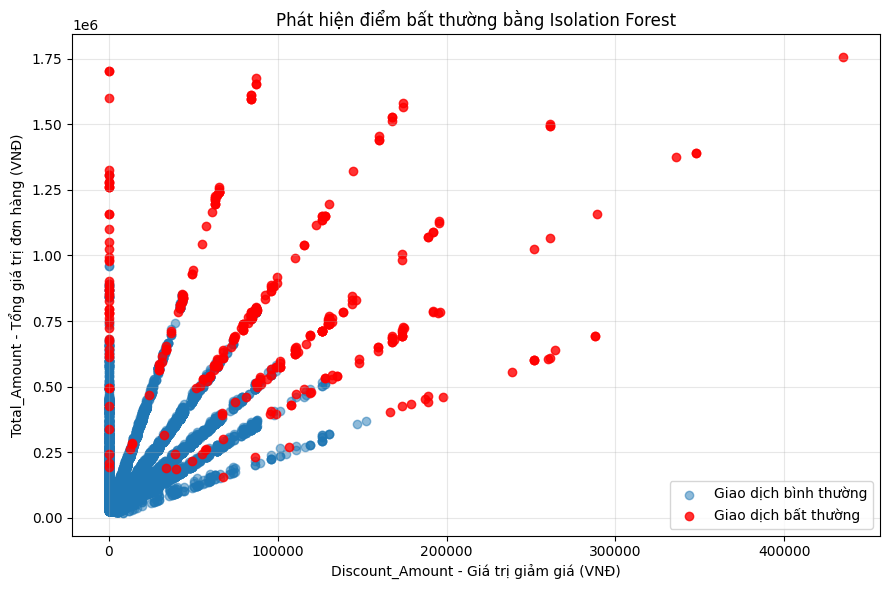

In [30]:

import matplotlib.pyplot as plt

# Tách giao dịch theo kết quả Isolation Forest
normal_data = df[df["IF_Anomaly_Final"] == 0]
anomaly_data = df[df["IF_Anomaly_Final"] == 1]

plt.figure(figsize=(9, 6))

# Giao dịch bình thường
plt.scatter(
    normal_data["Discount_Amount"],
    normal_data["Total_Amount"],
    label="Giao dịch bình thường",
    alpha=0.5
)

# Giao dịch bất thường hiển thị màu đỏ
plt.scatter(
    anomaly_data["Discount_Amount"],
    anomaly_data["Total_Amount"],
    color="red",
    label="Giao dịch bất thường",
    alpha=0.8
)

plt.xlabel("Discount_Amount - Giá trị giảm giá (VNĐ)")
plt.ylabel("Total_Amount - Tổng giá trị đơn hàng (VNĐ)")
plt.title("Phát hiện điểm bất thường bằng Isolation Forest")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [31]:

from sklearn.metrics import confusion_matrix, classification_report

print("Ma trận đối chiếu nhãn gốc và nhãn Isolation Forest:")
print(
    confusion_matrix(
        df["Is_Anomaly"],
        df["IF_Anomaly_Final"],
        labels=[0, 1]
    )
)

print("\nBáo cáo phân loại:")
print(
    classification_report(
        df["Is_Anomaly"],
        df["IF_Anomaly_Final"],
        labels=[0, 1],
        target_names=["Bình thường", "Bất thường"],
        zero_division=0
    )
)


Ma trận đối chiếu nhãn gốc và nhãn Isolation Forest:
[[7825  325]
 [ 335   15]]

Báo cáo phân loại:
              precision    recall  f1-score   support

 Bình thường       0.96      0.96      0.96      8150
  Bất thường       0.04      0.04      0.04       350

    accuracy                           0.92      8500
   macro avg       0.50      0.50      0.50      8500
weighted avg       0.92      0.92      0.92      8500



In [32]:

print("Các cột phân cụm hiện có:")
print([
    col for col in df.columns
    if "Cluster" in col
])

print("\nKiểm tra biến rfm:")
print("rfm tồn tại:", "rfm" in globals())

if "rfm" in globals():
    print("Các cột trong rfm:", rfm.columns.tolist())


Các cột phân cụm hiện có:
[]

Kiểm tra biến rfm:
rfm tồn tại: True
Các cột trong rfm: ['Customer_ID', 'Recency', 'Frequency', 'Monetary', 'Cluster']


In [33]:

import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Chỉ sử dụng các đơn hàng đã hoàn thành
df_rfm_source = df[
    df["Order_Status"] == "Hoàn thành"
].copy()

df_rfm_source["Order_Date"] = pd.to_datetime(
    df_rfm_source["Order_Date"],
    errors="coerce"
)

# Xác định ngày tham chiếu để tính Recency
snapshot_date = (
    df_rfm_source["Order_Date"].max()
    + pd.Timedelta(days=1)
)

# Tính các chỉ số RFM theo khách hàng
rfm = df_rfm_source.groupby("Customer_ID").agg(
    Recency=(
        "Order_Date",
        lambda x: (snapshot_date - x.max()).days
    ),
    Frequency=("Order_ID", "nunique"),
    Monetary=("Total_Amount", "sum")
).reset_index()

print("Số đơn hàng hoàn thành:", len(df_rfm_source))
print("Kích thước bảng RFM:", rfm.shape)
print("Số khách hàng:", rfm["Customer_ID"].nunique())

print("\n5 dòng đầu của bảng RFM:")
print(rfm.head())


Số đơn hàng hoàn thành: 6926
Kích thước bảng RFM: (1393, 4)
Số khách hàng: 1393

5 dòng đầu của bảng RFM:
  Customer_ID  Recency  Frequency  Monetary
0  CUST-00001       27          6   1380700
1  CUST-00002      199          2    525250
2  CUST-00003       46          4   1126600
3  CUST-00004       36          7   1234850
4  CUST-00005       98          4   1129550


In [34]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Chuẩn hóa ba chỉ số RFM
rfm_features = rfm[["Recency", "Frequency", "Monetary"]]

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

# Phân cụm khách hàng với K = 3
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

# Thống kê số khách hàng và đặc điểm trung bình của từng cụm
cluster_summary = rfm.groupby("Cluster").agg(
    So_khach_hang=("Customer_ID", "count"),
    Recency_TB=("Recency", "mean"),
    Frequency_TB=("Frequency", "mean"),
    Monetary_TB=("Monetary", "mean")
).round(2)

print("Số khách hàng trong từng cụm:")
print(rfm["Cluster"].value_counts().sort_index())

print("\nThống kê các cụm khách hàng:")
print(cluster_summary)


Số khách hàng trong từng cụm:
Cluster
0    215
1    481
2    697
Name: count, dtype: int64

Thống kê các cụm khách hàng:
         So_khach_hang  Recency_TB  Frequency_TB  Monetary_TB
Cluster                                                      
0                  215      157.16          2.87    665835.12
1                  481       33.28          7.20   1788366.01
2                  697       41.26          4.08    820967.00


In [35]:

# Tạo bảng ánh xạ khách hàng sang nhãn cụm
cluster_mapping = rfm[["Customer_ID", "Cluster"]].rename(
    columns={"Cluster": "Cluster_Label"}
)

# Ghép nhãn cụm vào dữ liệu giao dịch gốc
df = df.drop(columns=["Cluster_Label"], errors="ignore")

df = df.merge(
    cluster_mapping,
    on="Customer_ID",
    how="left",
    validate="many_to_one"
)

print("Kích thước dữ liệu sau khi gắn nhãn:", df.shape)

print("\nPhân bố nhãn cụm trên dữ liệu giao dịch:")
print(df["Cluster_Label"].value_counts(dropna=False).sort_index())

print("\nSố giao dịch chưa có nhãn cụm:")
print(df["Cluster_Label"].isnull().sum())

print("\nKiểm tra các cột kết quả:")
print([
    col for col in [
        "Customer_ID",
        "Cluster_Label",
        "Is_Anomaly",
        "IF_Anomaly_Final"
    ]
    if col in df.columns
])


Kích thước dữ liệu sau khi gắn nhãn: (8500, 32)

Phân bố nhãn cụm trên dữ liệu giao dịch:
Cluster_Label
0.0     897
1.0    3961
2.0    3634
NaN       8
Name: count, dtype: int64

Số giao dịch chưa có nhãn cụm:
8

Kiểm tra các cột kết quả:
['Customer_ID', 'Cluster_Label', 'Is_Anomaly', 'IF_Anomaly_Final']


In [36]:

# Kiểm tra các giao dịch chưa được gán nhãn cụm
unassigned = df[df["Cluster_Label"].isna()].copy()

print("Số giao dịch chưa có nhãn:", len(unassigned))

print("\nTrạng thái đơn hàng:")
print(unassigned["Order_Status"].value_counts(dropna=False))

print("\nThông tin các giao dịch:")
print(
    unassigned[
        ["Order_ID", "Customer_ID", "Order_Status", "Total_Amount"]
    ]
)


Số giao dịch chưa có nhãn: 8

Trạng thái đơn hàng:
Order_Status
Đang vận chuyển         4
Đã hủy                  2
Hoàn trả / Khiếu nại    2
Name: count, dtype: int64

Thông tin các giao dịch:
             Order_ID Customer_ID          Order_Status  Total_Amount
705   TTS-2024-006582  CUST-01244       Đang vận chuyển        143050
1949  TTS-2024-003282  CUST-01360                Đã hủy         95750
2640  TTS-2024-005583  CUST-00345                Đã hủy        165000
4436  TTS-2024-004053  CUST-00696       Đang vận chuyển        207250
4736  TTS-2024-001775  CUST-01137  Hoàn trả / Khiếu nại        198400
6244  TTS-2024-000359  CUST-01360       Đang vận chuyển        399000
6372  TTS-2024-002676  CUST-00345       Đang vận chuyển        124600
7889  TTS-2024-003135  CUST-00345  Hoàn trả / Khiếu nại        107100


In [37]:

# Kiểm tra các giao dịch chưa được phân cụm
unassigned = df[df["Cluster_Label"].isna()]

print("Số giao dịch chưa có nhãn:", len(unassigned))
print("\nTrạng thái của các giao dịch:")
print(unassigned["Order_Status"].value_counts())

print(
    "\nSố giao dịch chưa có nhãn nhưng thuộc đơn hoàn thành:",
    (unassigned["Order_Status"] == "Hoàn thành").sum()
)


Số giao dịch chưa có nhãn: 8

Trạng thái của các giao dịch:
Order_Status
Đang vận chuyển         4
Đã hủy                  2
Hoàn trả / Khiếu nại    2
Name: count, dtype: int64

Số giao dịch chưa có nhãn nhưng thuộc đơn hoàn thành: 0


In [41]:

# Xử lý các giao dịch chưa có nhãn RFM
df["Cluster_Label"] = df["Cluster_Label"].astype("object")

df.loc[
    df["Cluster_Label"].isna(),
    "Cluster_Label"
] = "Chưa có đơn hoàn thành"

# Kiểm tra lại kết quả
print("Phân bố nhãn RFM sau khi xử lý:")
print(df["Cluster_Label"].value_counts(dropna=False))

print(
    "\nSố nhãn còn thiếu:",
    df["Cluster_Label"].isna().sum()
)


Phân bố nhãn RFM sau khi xử lý:
Cluster_Label
1.0                       3961
2.0                       3634
0.0                        897
Chưa có đơn hoàn thành       8
Name: count, dtype: int64

Số nhãn còn thiếu: 0


In [42]:

# Kiểm tra dữ liệu trước khi xuất
print("Kích thước dữ liệu:", df.shape)
print("Số nhãn cụm bị thiếu:", df["Cluster_Label"].isna().sum())

# Xuất dữ liệu kết quả
output_file = "tiktok_shop_sales_ml_results.csv"

df.to_csv(output_file, index=False, encoding="utf-8-sig")

print("\nĐã xuất file:", output_file)
print("Số dòng trong file:", len(df))
print("Có cột Cluster_Label:", "Cluster_Label" in df.columns)


Kích thước dữ liệu: (8500, 32)
Số nhãn cụm bị thiếu: 0

Đã xuất file: tiktok_shop_sales_ml_results.csv
Số dòng trong file: 8500
Có cột Cluster_Label: True


In [43]:

from google.colab import files

files.download("tiktok_shop_sales_ml_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>